In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.9/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.9/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
from pyCRLD.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA
from pyCRLD.Utils.Trajectories1D import trajectories_1D 
from pyCRLD.Utils.PhasePlot import phaseplot
import numpy as np

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)

In [ ]:
mae = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.9, choice_intensities=4., use_prefactor=True)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
mae_d = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                   learning_rates=0.1, discount_factors=0.9,
                   choice_intensities=4, Rmin=-1, Rmax=2,
                   method='mean', use_prefactor=True)

In [ ]:
X = np.ones((1, 2, 2)) * 0.5

In [ ]:
mae.Risa(X)

Array([[[0.5, 0.8],
        [0. , 0. ]]], dtype=float32)

In [ ]:
mae.Qisa(X)

Array([[[4.109573 , 3.9117007],
        [1.369148 , 1.120212 ]]], dtype=float32)

In [ ]:
rounds = 10000
qs = np.zeros((1, 2, 2, rounds))
for i in range(rounds):
    x = np.random.rand(1, 2, 2)
    q = mae.Qisa(x)
    qs[:, :, :, i] = q

In [ ]:
np.sum(qs > 1)

1636

In [ ]:
Risar = mae_d.Risar(X)
gps = mae_d.gridpoints
np.einsum('ijkl,l->ijk', Risar, gps)

array([[[ 5.00000012e-01,  8.00000020e-01],
        [-3.86366088e-09, -1.45824229e-09]]])

In [ ]:
mae.Qisa(X)

Array([[[0.4109574 , 0.39117017],
        [0.13691485, 0.11202123]]], dtype=float32)

In [ ]:
Qisaq = mae_d.Qisaq(X)
np.einsum('ijkl,l->ijk', Qisaq, gps)

array([[[0.38606983, 0.37375001],
        [0.14563046, 0.12447054]]])

In [ ]:
sigmas = np.linspace(0.05, 2.5, 50)
sigmas

array([0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55,
       0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  , 1.05, 1.1 ,
       1.15, 1.2 , 1.25, 1.3 , 1.35, 1.4 , 1.45, 1.5 , 1.55, 1.6 , 1.65,
       1.7 , 1.75, 1.8 , 1.85, 1.9 , 1.95, 2.  , 2.05, 2.1 , 2.15, 2.2 ,
       2.25, 2.3 , 2.35, 2.4 , 2.45, 2.5 ])

In [ ]:
xs = np.linspace(0, 1, 11)
xs[0] = 0.001
xs[-1] = 0.999

In [ ]:
err = np.zeros((len(sigmas), len(xs), 2))

In [ ]:
comp = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.9, 
                  choice_intensities=4., use_prefactor=True)
ref = np.zeros((len(xs), 2))
X = np.ones((1, 2, 2)) * -1
for j, x in enumerate(xs):
    X[:, :, 0] = x
    X[:, :, 1] = 1 - x
    traj, fpreached = comp.trajectory(X, 150)
    ref[j, 0] = traj[-1, 0, 0, 0]
    ref[j, 1] = traj[-1, 0, 1, 0]
    
for i, s in enumerate(sigmas):
    mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=s, 
                     learning_rates=0.1, discount_factors=0.9,
                     choice_intensities=4, Rmin=0, Rmax=1,
                     method='mean', use_prefactor=True)
    X = np.ones((1, 2, 2)) * -1
    for j, x in enumerate(xs):
        X[:, :, 0] = x
        X[:, :, 1] = 1 - x
        traj, fpreached = mae.trajectory(X, 150)
        err[i, j, 0] = np.abs(traj[-1, 0, 0, 0] - ref[j, 0])
        err[i, j, 1] = np.abs(traj[-1, 0, 1, 0] - ref[j, 1])
        
    print('done')

done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done


In [ ]:
mean_err = np.mean(err, axis=1)

Text(0.5, 1.0, 'degraded state')

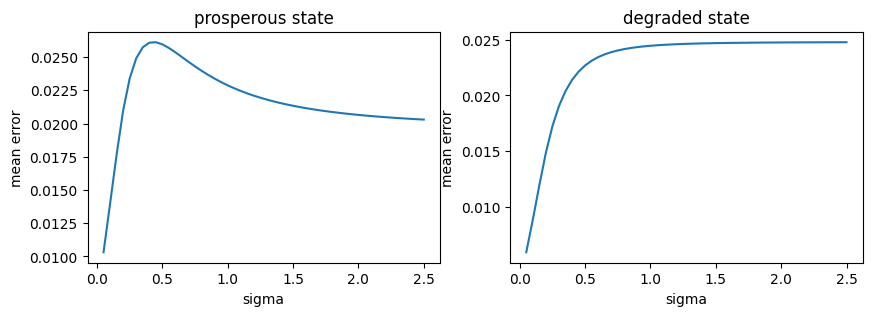

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
axes = [ax1, ax2]
for i, ax in enumerate(axes):
    ax.plot(sigmas, mean_err[:, i])
    ax.set_xlabel("sigma")
    ax.set_ylabel("mean error")
ax1.set_title("prosperous state")
ax2.set_title("degraded state")

In [ ]:
mean_err[:, 1]

array([0.05393612, 0.04085101, 0.0448488 , 0.05177265, 0.0580532 ,
       0.06350611, 0.06827526, 0.07252582, 0.07639709, 0.08000653,
       0.08346021, 0.08685247, 0.09026759, 0.09377318, 0.09741317,
       0.10120565, 0.10514395, 0.10919998, 0.11333394, 0.11749809,
       0.12164619, 0.12573611, 0.12973286, 0.13360793, 0.13734285,
       0.14092436, 0.14434458, 0.14760158, 0.15069558, 0.15363003,
       0.15640963, 0.15904239, 0.16153321, 0.16389107, 0.1661225 ,
       0.16823543, 0.17023668, 0.17213401, 0.17393407, 0.17564227,
       0.17726446, 0.17880717, 0.18027505, 0.18167275, 0.18300414,
       0.18427415, 0.18548588, 0.18664351, 0.18774968, 0.18880807])

In [ ]:
def plot_Risar(a, Rr=mae_d.Risar, gpoints=mae_d.gridpoints, wdth=mae_d.gridwidth):
    fig, axes = plt.subplots(1, 3, figsize=(12,3))
    for s_, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Rr[i,s,a,s_,:], width=0.95*wdth, color='k')
        r = env.R[i,s,a,s_]
        rm = np.dot(gpoints, Rr[i,s,a,s_,:])
        ax.plot([r, r], [0.0, 0.055], c='blue', lw=5)
        ax.plot([rm, rm], [0.0, 0.05], c='red', lw=5)
        ax.set_xlabel("Risjasr")
        ax.set_title("Reward for agent "+str(i)+" in state "+str(s_))
        ax.set_ylim([0, np.max(Rr[:,:,:,s_])+0.01])
    

plot_Risjasr(i=0, s=0, a=0, Rr=qb.Rr, gpoints=qb.gridpoints, wdth=qb.gridwidth)